**Laptop Sales at a London Computer Chain**


In [ ]:
# First make Drive available to Colab
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive -name "requirements.txt"
!pip install -r /content/drive/MyDrive/requirements.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab Notebooks/requirements.txt
/content/drive/MyDrive/requirements.txt


In [ ]:
import calendar
import os
import matplotlib.pyplot as plt
import mlba
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from adjustText import adjust_text
from pandas.plotting import parallel_coordinates, scatter_matrix
from sklearn import preprocessing
%matplotlib inline


no display found. Using non-interactive Agg backend


In [ ]:
# Load data
df = mlba.load_data('LaptopSales.txt')

# View data
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297572 entries, 0 to 297571
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   Date                    297364 non-null  object 
 1   Configuration           297572 non-null  int64  
 2   Customer Postcode       297572 non-null  object 
 3   Store Postcode          297572 non-null  object 
 4   Retail Price            284129 non-null  float64
 5   Screen Size (Inches)    297572 non-null  int64  
 6   Battery Life (Hours)    297572 non-null  int64  
 7   RAM (GB)                297572 non-null  int64  
 8   Processor Speeds (GHz)  297572 non-null  float64
 9   Integrated Wireless?    297572 non-null  object 
 10  HD Size (GB)            297572 non-null  int64  
 11  Bundled Applications?   297572 non-null  object 
 12  customer X              297572 non-null  int64  
 13  customer Y              297572 non-null  int64  
 14  store X             

a. Price Questions:

i. At what price are the laptops actually selling?

count    284129.000000
mean        508.125936
std         104.611789
min         168.000000
25%         440.000000
50%         500.000000
75%         575.000000
max         890.000000
Name: Retail Price, dtype: float64


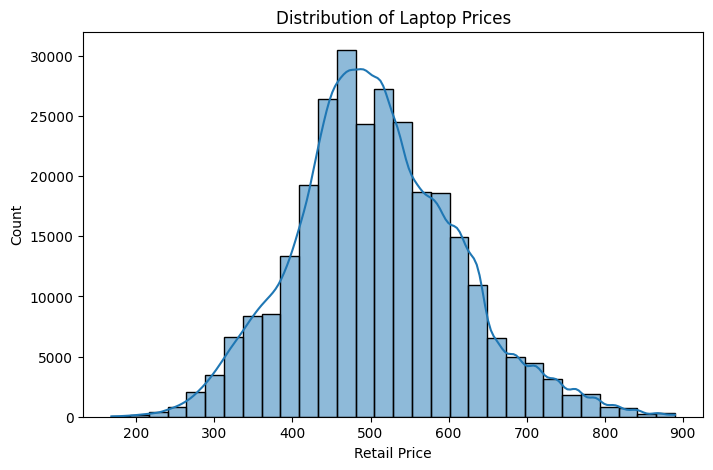

In [ ]:
print(df['Retail Price'].describe())

plt.figure(figsize=(8,5))
sns.histplot(df['Retail Price'], bins=30, kde=True)
plt.title('Distribution of Laptop Prices')
plt.show()

ii. Does price change with time? Hint: Make sure that the date column is recog-
nized as such (check Column Info). JMP will then allow dynamic transforma-
tions and allow you to plot the data by weekly or monthly aggregates, or even
by day of week.

/tmp/ipykernel_6252/1280023390.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_price = df.groupby(pd.Grouper(key='Date', freq='M'))['Retail Price'].mean()


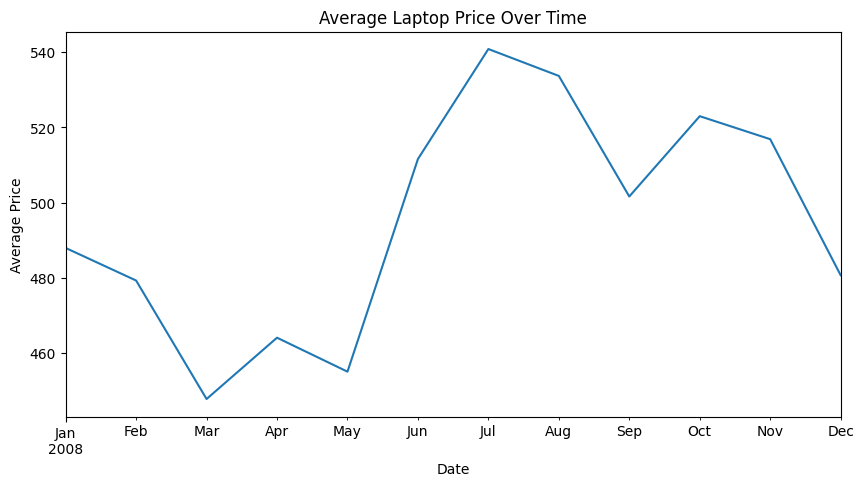

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])

monthly_price = df.groupby(pd.Grouper(key='Date', freq='M'))['Retail Price'].mean()
plt.figure(figsize=(10,5))
monthly_price.plot()
plt.title('Average Laptop Price Over Time')
plt.ylabel('Average Price')
plt.show()

iii. Are prices consistent over retail outlets?

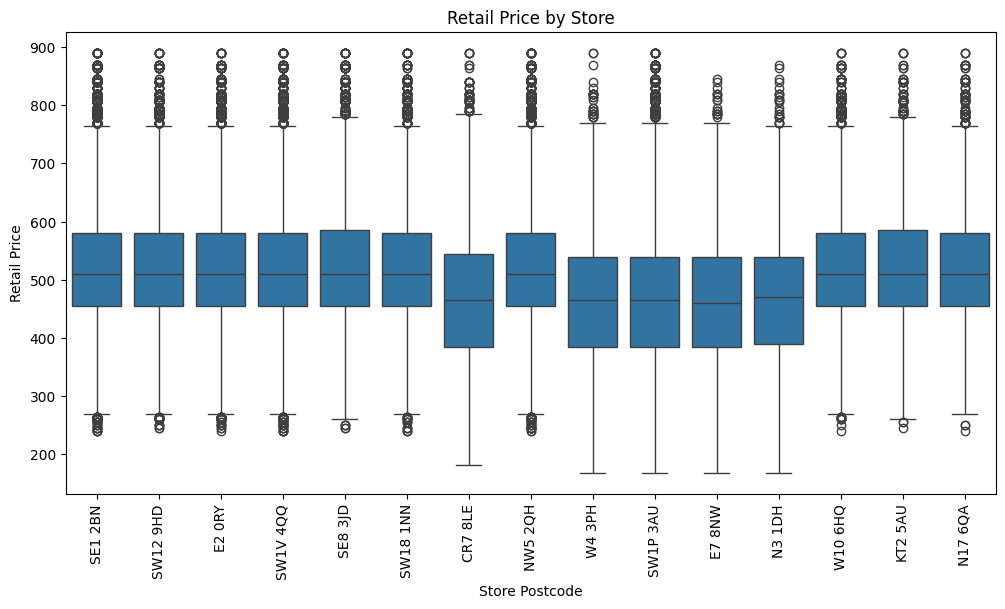

In [ ]:
top_stores = df['Store Postcode'].value_counts().head(15).index

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df[df['Store Postcode'].isin(top_stores)],
    x='Store Postcode',
    y='Retail Price')
plt.xticks(rotation=90)
plt.title('Retail Price by Store')
plt.show()

iv. How does price change with configuration?

In [ ]:
config_price = df.groupby('Configuration')['Retail Price'].mean()

plt.figure(figsize=(10,5))
config_price.plot(kind='bar')
plt.title('Average Price by Configuration')
plt.ylabel('Average Price')
plt.show()

b. Location Questions:

i. Where are the stores and customers located?


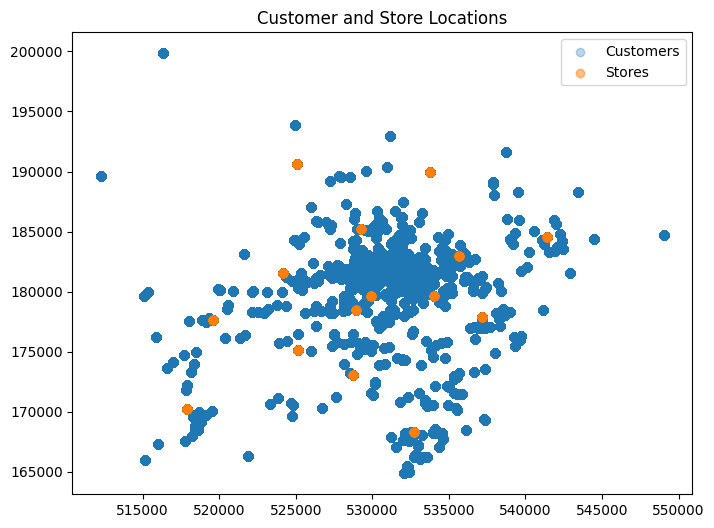

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df['customer X'],
    df['customer Y'],
    alpha=0.3,
    label='Customers')

plt.scatter(
    df['store X'],
    df['store Y'],
    alpha=0.5,
    label='Stores')

plt.legend()
plt.title('Customer and Store Locations')
plt.show()


ii. Which stores are selling the most?


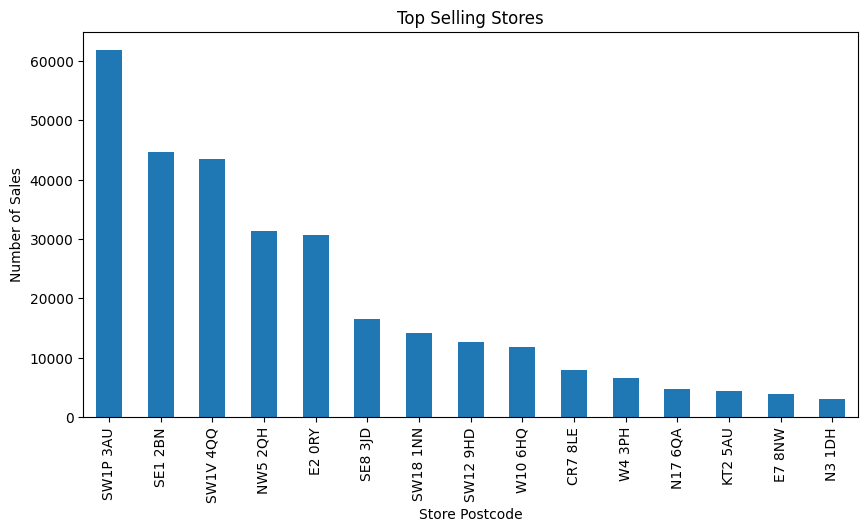

In [ ]:
store_sales = df['Store Postcode'].value_counts()
store_sales.head(15).plot( kind='bar',figsize=(10,5))
plt.title('Top Selling Stores')
plt.ylabel('Number of Sales')
plt.show()

iii. How far would customers travel to buy a laptop?

In [ ]:
#  Euclidean distance between customer and store
df['Distance'] = np.sqrt((df['customer X'] - df['store X'])**2 +(df['customer Y'] - df['store Y'])**2)
print(df['Distance'].describe())

count    297424.000000
mean       3680.240456
std        2078.151711
min           0.000000
25%        2424.680804
50%        3369.826702
75%        4347.773338
max       19892.140408
Name: Distance, dtype: float64


iv. Try an alternative way of looking at how far customers traveled. Do this by creating a new data column that computes the distance between customer and store

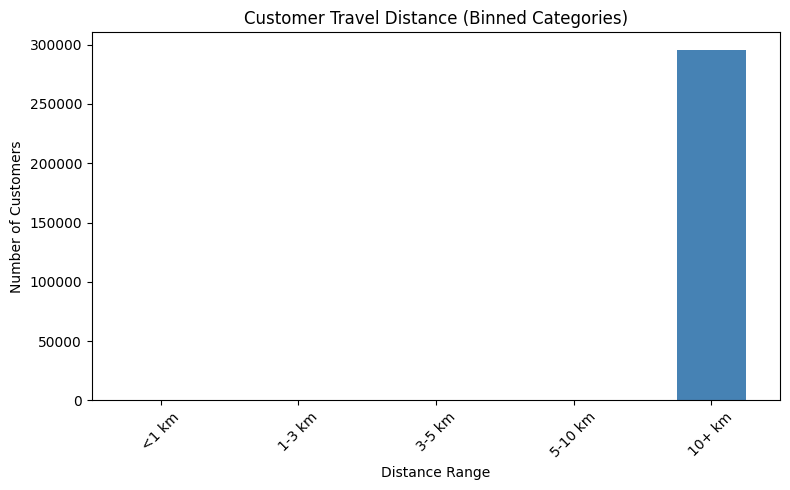

In [ ]:
df['Distance Category'] = pd.cut(df['Distance'], bins=[0, 1, 3, 5, 10, np.inf],
                                  labels=['<1 km', '1-3 km', '3-5 km', '5-10 km', '10+ km'])

plt.figure(figsize=(8, 5))
df['Distance Category'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Customer Travel Distance (Binned Categories)')
plt.xlabel('Distance Range')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

c. Revenue Questions:


i. How do the sales volume in each store relate to Acell’s revenues?


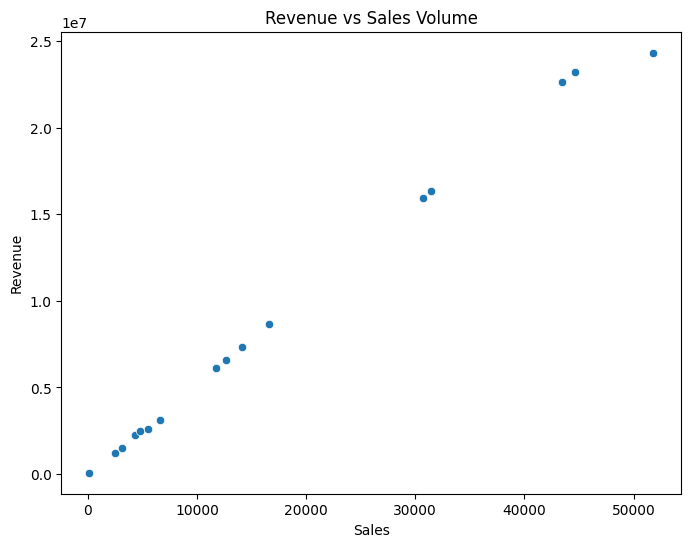

In [ ]:

df['Revenue'] = df['Retail Price']
#Revenue vs Sales Volume
store_rev = df.groupby('Store Postcode').agg(
    Revenue=('Revenue','sum'),
    Sales=('Revenue','count'))

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=store_rev,
    x='Sales',
    y='Revenue')

plt.title('Revenue vs Sales Volume')
plt.show()

ii. How does this depend on the configuration?

               Total_Revenue   Avg_Price  Units_Sold
Configuration                                       
1                    85454.0  337.762846         253
2                    70406.0  288.549180         244
3                    99443.0  376.678030         264
4                    83245.0  329.031621         253
5                    91751.0  392.098291         234
...                      ...         ...         ...
860                 117438.0  711.745455         165
861                 131544.0  778.366864         169
862                 128364.0  725.220339         177
863                 128499.0  834.409091         154
864                 123246.0  790.038462         156

[864 rows x 3 columns]


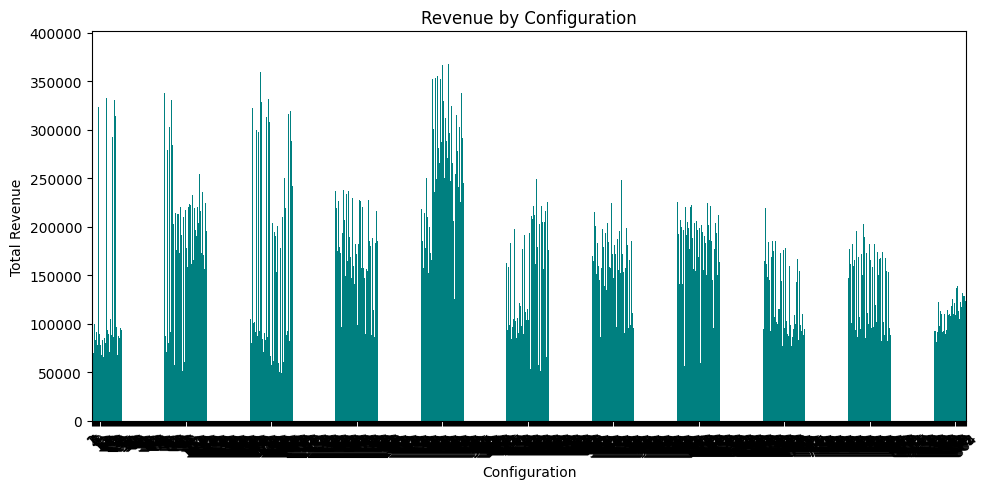

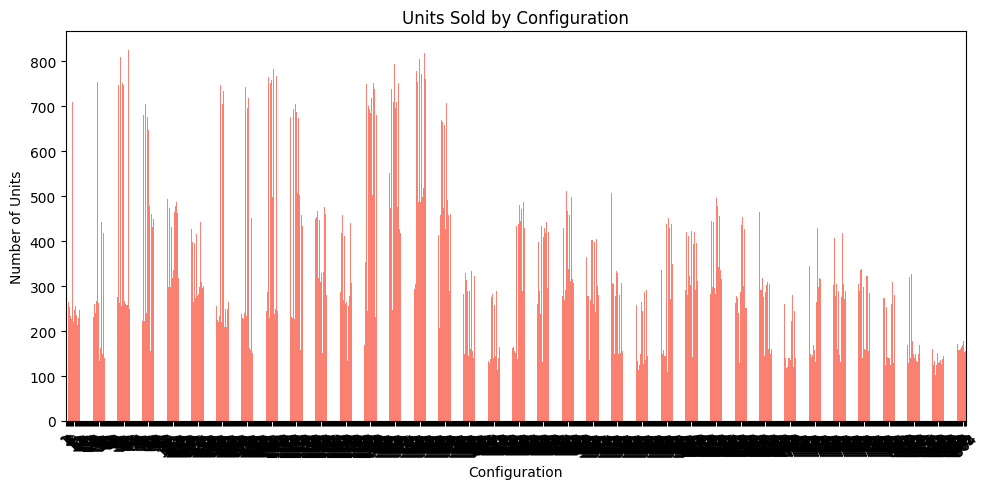

In [ ]:
# Revenue by configuration
config_rev = df.groupby('Configuration').agg(Total_Revenue=('Revenue', 'sum'),Avg_Price=('Retail Price', 'mean'),Units_Sold=('Revenue', 'count'))
print(config_rev)

#total revenue by configuration
plt.figure(figsize=(10, 5))
config_rev['Total_Revenue'].plot(kind='bar', color='teal')
plt.title('Revenue by Configuration')
plt.ylabel('Total Revenue')
plt.xlabel('Configuration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#units sold by configuration
plt.figure(figsize=(10, 5))
config_rev['Units_Sold'].plot(kind='bar', color='salmon')
plt.title('Units Sold by Configuration')
plt.ylabel('Number of Units')
plt.xlabel('Configuration')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

d. Configuration Questions:


i. What are the details of each configuration? How does this relate to price?


     Configuration   Avg_Price  Screen_Size  Battery_Life  RAM  \
0                1  337.762846         15.0           4.0  1.0   
1                2  288.549180         15.0           4.0  1.0   
2                3  376.678030         15.0           4.0  1.0   
3                4  329.031621         15.0           4.0  1.0   
4                5  392.098291         15.0           4.0  1.0   
..             ...         ...          ...           ...  ...   
859            860  711.745455         17.0           6.0  4.0   
860            861  778.366864         17.0           6.0  4.0   
861            862  725.220339         17.0           6.0  4.0   
862            863  834.409091         17.0           6.0  4.0   
863            864  790.038462         17.0           6.0  4.0   

     Processor_Speed  HD_Size  
0                1.5     40.0  
1                1.5     40.0  
2                1.5     80.0  
3                1.5     80.0  
4                1.5    120.0  
..             

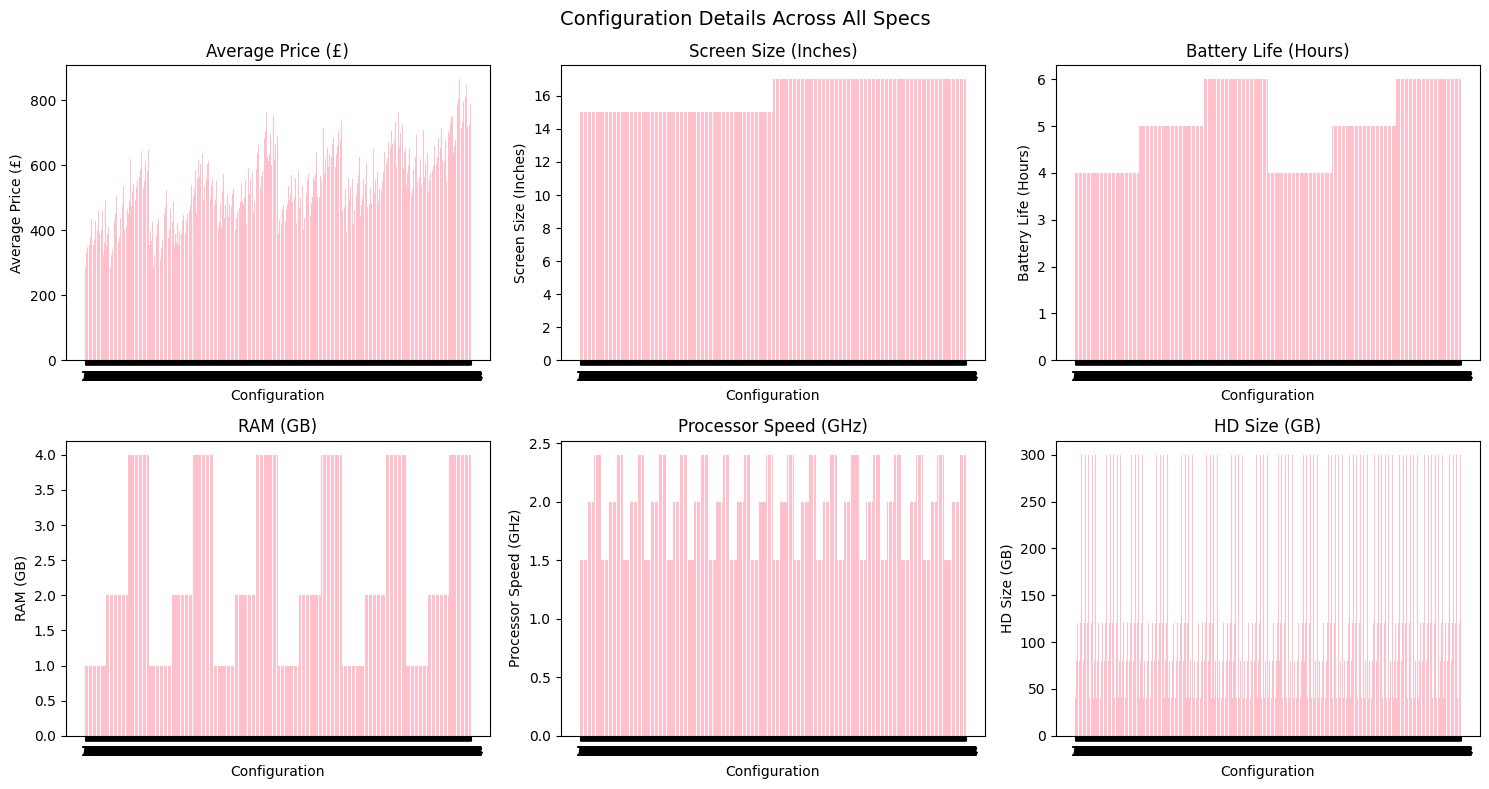

In [ ]:
# Details of each configuration and relation to price
config_summary = df.groupby('Configuration').agg(
    Avg_Price=('Retail Price', 'mean'),
    Screen_Size=('Screen Size (Inches)', 'mean'),
    Battery_Life=('Battery Life (Hours)', 'mean'),
    RAM=('RAM (GB)', 'mean'),
    Processor_Speed=('Processor Speeds (GHz)', 'mean'),
    HD_Size=('HD Size (GB)', 'mean')).reset_index()
print(config_summary)

# Bar chart for each spec across configurations
specs_raw = {'Avg_Price': 'Average Price (£)','Screen_Size': 'Screen Size (Inches)',
             'Battery_Life':'Battery Life (Hours)','RAM': 'RAM (GB)','Processor_Speed':
              'Processor Speed (GHz)','HD_Size': 'HD Size (GB)'}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, (col, label) in enumerate(specs_raw.items()):
    axes[i].bar(config_summary['Configuration'].astype(str),config_summary[col],
        color='pink')
    axes[i].set_title(label)
    axes[i].set_xlabel('Configuration')
    axes[i].set_ylabel(label)

plt.suptitle('Configuration Details Across All Specs', fontsize=14)
plt.tight_layout()
plt.show()

ii. Do all stores sell all configurations?

In [ ]:

# Do all stores sell all configurations?
num_configs = df['Configuration'].nunique()
configs_per_store = df.groupby('Store Postcode')['Configuration'].nunique()

all_sell_all = (configs_per_store == num_configs).all()
print(f"Total unique configurations: {num_configs}")
print(f"Do all stores sell all configurations? {all_sell_all}")

#  stores that do NOT sell all configurations
stores_missing = configs_per_store[configs_per_store < num_configs]
print(f"\nStores NOT selling all configurations: {len(stores_missing)}")
print(stores_missing.sort_values())


Total unique configurations: 864
Do all stores sell all configurations? False

Stores NOT selling all configurations: 7
Store Postcode
S1P 3AU    134
N3 1DH     798
E7 8NW     819
KT2 5AU    832
N17 6QA    840
W4 3PH     856
CR7 8LE    857
Name: Configuration, dtype: int64
